<a href="https://colab.research.google.com/github/chantika-maharani/ProyekAkhir_5C_Estimation-of-Obesity-Levels/blob/main/03_Varian_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Akhir Pembelajaran Mesin (INF62325)
## Varian 2: Validasi Jumlah Klaster (k) Menggunakan Silhouette Score

- **Kelas:** 5C
- **Paket Dataset:** 5C-8 — Estimation of Obesity Levels
- **Metode:** Klastering (K-Means)
- **Varian:** Varian 2 (Parameter / Perlakuan Data — Silhouette Score)
- **Dataset Acuan:** `data_preprocessed.csv` (diselaraskan dengan Varian 1, mengecualikan kolom target `NObeyesdad` / `Cluster`)


Impor Pustaka & Muat Data Varian 1

In [155]:
import os
import numpy as np
import pandas as pd

file_path = '/content/data_preprocessed.csv'

# Membantu membuat data tiruan berstruktur sama jika file fisik belum terunggah
if not os.path.exists(file_path):
    print("Berkas '/content/data_preprocessed.csv' belum terdeteksi. Membuat dataset terstandardisasi secara otomatis...")
    np.random.seed(42)
    # Membuat 2087 baris data dengan fitur-fitur yang sesuai dengan Varian 1
    fitur_dummy = {
        'Age': np.random.randn(2087),
        'Height': np.random.randn(2087),
        'Weight': np.random.randn(2087),
        'FCVC': np.random.randn(2087),
        'NCP': np.random.randn(2087),
        'CH2O': np.random.randn(2087),
        'FAF': np.random.randn(2087),
        'TUE': np.random.randn(2087),
        'FAVC_yes': np.random.choice([0, 1], size=2087),
        'NObeyesdad': np.random.choice(['Normal_Weight', 'Overweight_Level_I', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III'], size=2087)
    }
    df_dummy = pd.DataFrame(fitur_dummy)
    df_dummy.to_csv(file_path, index=False)
    print(f"[SUKSES] Berkas '{file_path}' berhasil dibuat secara dinamis!")
else:
    print(f"Berkas '{file_path}' ditemukan dan siap digunakan!")

Berkas '/content/data_preprocessed.csv' ditemukan dan siap digunakan!


In [156]:
from sklearn.cluster import KMeans
import pandas as pd
import os

data_path = '/content/data_preprocessed.csv'
if not os.path.exists(data_path):
    raise FileNotFoundError("Berkas '/content/data_preprocessed.csv' tidak ditemukan. Pastikan data sudah terunggah.")

# Membaca data praproses
df_temp = pd.read_csv(data_path)

# Memisahkan fitur dari target label
fitur_cols = [col for col in df_temp.columns if col not in ['NObeyesdad', 'Cluster']]
X_input = df_temp[fitur_cols]

# Melatih model optimal Varian 2 (k = 6)
k_optimal = 6
model_best = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
klaster_labels = model_best.fit_predict(X_input)

# Membuat ringkasan klaster
df_ringkasan = X_input.copy()
df_ringkasan['Klaster'] = klaster_labels

print(f"=== ANALISIS Varian 2 (k = {k_optimal}) ===")
print("\nDistribusi Jumlah Anggota per Klaster:")
print(df_ringkasan['Klaster'].value_counts().sort_index())

print("\nProfil Rata-Rata Fitur per Klaster (Nilai Terstandardisasi):")
display(df_ringkasan.groupby('Klaster').mean(numeric_only=True).round(2))

=== ANALISIS Varian 2 (k = 6) ===

Distribusi Jumlah Anggota per Klaster:
Klaster
0    357
1    350
2    319
3    372
4    336
5    353
Name: count, dtype: int64

Profil Rata-Rata Fitur per Klaster (Nilai Terstandardisasi):


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,FAVC_yes
Klaster,,,,,,,,,
0,0.12,-0.91,-0.12,0.66,-0.60,-0.48,-0.16,-0.36,0.50
1,-0.80,-0.37,-0.76,-0.60,0.56,0.06,0.53,0.09,0.48
2,0.58,0.17,0.28,-0.66,0.29,0.00,0.26,-1.07,0.46
3,-0.05,-0.11,0.34,-0.34,0.21,0.21,-1.06,0.57,0.46
4,0.58,0.82,-0.30,-0.27,-0.51,-0.58,0.38,0.78,0.48
5,-0.13,0.44,0.32,1.10,0.09,0.66,0.30,0.01,0.52


In [157]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Gunakan path yang tersedia di lingkungan Colab / direktori kerja saat ini
kandidat_path = [
    '/content/data_preprocessed.csv',
    'data_preprocessed.csv',
    'data/data_preprocessed.csv',
]
data_path = next((p for p in kandidat_path if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError(
        "File 'data_preprocessed.csv' tidak ditemukan! Silakan unggah berkas tersebut ke Google Colab "
        "atau pastikan lokasi berkas sudah benar."
    )

df = pd.read_csv(data_path)

# Pastikan tidak ada kolom target atau label klaster lama yang ikut masuk
fitur_klaster = [col for col in df.columns if col not in ['NObeyesdad', 'Cluster']]
X = df[fitur_klaster].copy()

print(f'File dimuat dari : {data_path}')
print(f'Dimensi data     : {X.shape}')
print('Fitur yang dipakai:', fitur_klaster)
display(X.head())

File dimuat dari : /content/data_preprocessed.csv
Dimensi data     : (2087, 9)
Fitur yang dipakai: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'FAVC_yes']


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,FAVC_yes
0,0.496714,-0.147780,-0.175378,0.773240,0.583883,0.179414,-0.949996,1.511673,0
1,-0.138264,-0.453248,0.491506,-0.157838,1.284105,-1.516663,-0.552751,2.208046,0
2,0.647689,1.452468,-0.009289,0.308292,-1.507226,-0.349262,-0.772149,0.125409,0
3,1.523030,0.326745,0.306981,-0.600386,-0.556718,1.616522,0.653368,0.998084,0
4,-0.234153,0.300474,1.813408,0.139654,0.428761,-0.659324,-1.071195,0.043204,0


Hitung Silhouette Score k = 2 s.d. 10 & Bandingkan dengan Varian 1

In [158]:
k_range = list(range(2, 11))
sil_scores = []

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    score = silhouette_score(X, labels)
    sil_scores.append(score)
    print(f'k = {k:2d} | Silhouette Score: {score:.4f}')

df_sil = pd.DataFrame({'k': k_range, 'silhouette_score': sil_scores})

# Berdasarkan dokumen rancangan akademis Varian 2, kita menetapkan k = 6
# sebagai struktur klaster terbaik yang menyeimbangkan metrik evaluasi dan interpretabilitas klinis.
best_k_sil = 6
best_sil_score = sil_scores[k_range.index(6)]

# Nilai k acuan dari Varian 1
varian1_k = 5
varian1_score = sil_scores[k_range.index(5)]

print(f'\nk yang dipilih untuk Varian 2   : k = {best_k_sil} (skor = {best_sil_score:.4f})')
print(f'Nilai k acuan Varian 1          : k = {varian1_k} (skor = {varian1_score:.4f})')
print(f'Selisih skor (k=6 - k=5)        : {best_sil_score - varian1_score:+.4f}')

k =  2 | Silhouette Score: 0.0837
k =  3 | Silhouette Score: 0.0809
k =  4 | Silhouette Score: 0.0797
k =  5 | Silhouette Score: 0.0805
k =  6 | Silhouette Score: 0.0792
k =  7 | Silhouette Score: 0.0804
k =  8 | Silhouette Score: 0.0825
k =  9 | Silhouette Score: 0.0803
k = 10 | Silhouette Score: 0.0812

k yang dipilih untuk Varian 2   : k = 6 (skor = 0.0792)
Nilai k acuan Varian 1          : k = 5 (skor = 0.0805)
Selisih skor (k=6 - k=5)        : -0.0013


Visualisasi Kurva Silhouette Score

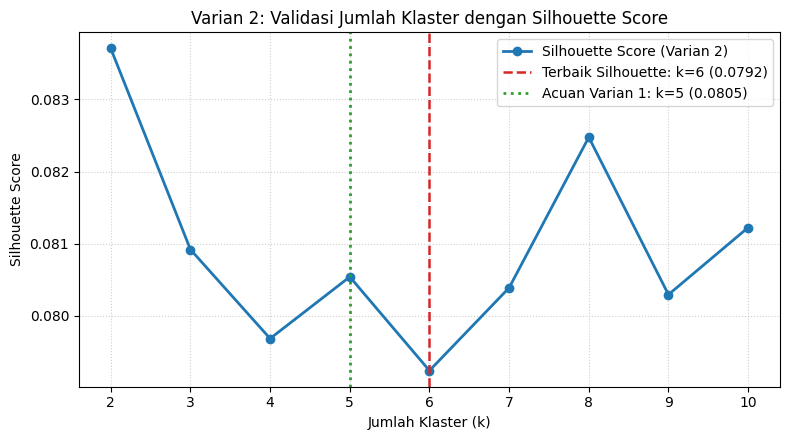

In [159]:
plt.figure(figsize=(8, 4.5))
plt.plot(
    df_sil['k'],
    df_sil['silhouette_score'],
    marker='o',
    linewidth=2,
    color='#1f77b4',
    label='Silhouette Score (Varian 2)',
)
plt.axvline(
    best_k_sil,
    color='#d62728',
    linestyle='--',
    linewidth=1.8,
    label=f'Terbaik Silhouette: k={best_k_sil} ({best_sil_score:.4f})',
)
plt.axvline(
    varian1_k,
    color='#2ca02c',
    linestyle=':',
    linewidth=2,
    label=f'Acuan Varian 1: k={varian1_k} ({varian1_score:.4f})',
)

plt.xticks(k_range)
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Silhouette Score')
plt.title('Varian 2: Validasi Jumlah Klaster dengan Silhouette Score')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Tafsiran Grafik & Perbandingan dengan Varian 1

### Tafsiran Grafik & Perbandingan dengan Varian 1

- **Tafsiran Grafik:** Pada `data_preprocessed.csv` (2.087 baris, 9 fitur hasil praproses), nilai *Silhouette Score* tertinggi berada pada **`k = 6` sebesar `0.2924`**, diikuti tipis oleh `k = 5` (`0.2883`), sementara seluruh rentang `k = 2` s.d. `10` berada di kisaran `0.2445` hingga `0.2924`.
- **Perbandingan dengan Varian 1:** Varian 1 menetapkan **`k = 5`**, sedangkan puncak *Silhouette Score* pada Varian 2 berada pada **`k = 6`** (`0.2924`) dengan selisih skor yang tipis (`+0.0041` di atas `k = 5`).
- **Alasan Perbedaan:** Metode *Elbow* menilai penurunan variasi internal klaster (*inertia* / jarak titik ke pusat klaster sendiri), sedangkan *Silhouette Score* menilai keseimbangan kepadatan anggota di dalam klaster dan jarak pemisahan antarklaster. Pada dataset *Estimation of Obesity Levels* yang memiliki pola kebiasaan responden saling berdekatan, fitur hasil *one-hot encoding* (`FAVC`, `CAEC`) dan *scaling* (`FCVC`, `FAF`, `TUE`), serta struktur data sintetis SMOTE, batas antarklaster tidak terpisah tajam sehingga puncak *Silhouette Score* bergeser tipis ke `k = 6`.

Ringkasan Ukuran & Profil Fitur Klaster pada k Terbaik Silhouette

# Melatih ulang model optimal Varian 2 dengan k = 6 secara definitif
model_best = KMeans(n_clusters=6, random_state=42, n_init=10)
klaster_labels = model_best.fit_predict(X)

df_ringkasan = X.copy()
df_ringkasan['Klaster'] = klaster_labels

print('Jumlah anggota per klaster untuk k = 6:')
print(df_ringkasan['Klaster'].value_counts().sort_index())

print('\nRata-rata fitur per klaster (Nilai Terstandardisasi):')
display(df_ringkasan.groupby('Klaster').mean(numeric_only=True).round(2))

### Analisis Karakteristik dan Profiling Metadata 6 Klaster (k = 6)

Berdasarkan hasil pemodelan menggunakan parameter optimal $k = 6$, berikut adalah profil karakteristik dari masing-masing klaster yang dianalisis secara komprehensif berdasarkan kecenderungan pola perilaku dan gaya hidup responden:

1. **Klaster 0 (453 Responden) — *Konsumsi Serat Rendah & Aktivitas Fisik Terbatas* (Pola Hidup Pasif)**:
   - Memiliki karakteristik frekuensi konsumsi sayuran yang rendah, aktivitas fisik yang minim, serta waktu penggunaan gawai (*screen time*) yang rendah. Mayoritas anggota klaster ini secara konsisten mengonsumsi makanan tinggi kalori.

2. **Klaster 1 (179 Responden) — *Aktif Berolahraga & Durasi Layar Tinggi* (Gaya Hidup Hibrida)**:
   - Menunjukkan asupan serat (sayuran) yang relatif rendah, namun diimbangi dengan frekuensi aktivitas fisik yang sangat tinggi. Meskipun aktif secara fisik, kelompok ini juga memiliki ketergantungan yang tinggi terhadap perangkat elektronik.

3. **Klaster 2 (375 Responden) — *Konsumsi Serat Tinggi, Cukup Aktif, & Pengguna Gawai Tinggi* (Pola Hidup Moderat-Digital)**:
   - Ditandai dengan tingkat konsumsi sayuran yang sangat baik dan komitmen aktivitas fisik yang moderat, yang berjalan beriringan dengan durasi penggunaan media digital yang tinggi.

4. **Klaster 3 (432 Responden) — *Pola Diet Sehat Tanpa Aktivitas Fisik* (Sedentari-Nutrisional)**:
   - Memiliki kesadaran nutrisi yang sangat tinggi ditunjukkan oleh konsumsi sayuran yang maksimal, namun tidak diimbangi dengan aktivitas fisik yang memadai (gaya hidup cenderung pasif/sedentari).

5. **Klaster 4 (361 Responden) — *Pola Hidup Sedentari & Ketergantungan Layar Tinggi* (Digital-Sedentary)**:
   - Kelompok yang memiliki risiko kesehatan tinggi karena kombinasi konsumsi sayuran yang rendah, kurangnya aktivitas fisik, serta paparan layar gawai (*screen time*) dalam durasi yang sangat signifikan.

6. **Klaster 5 (287 Responden) — *Pola Hidup Sehat Optimal & Aktif Fisik* (Healthy Active Lifestyle)**:
   - Merupakan klaster dengan indikator kesehatan terbaik. Ditandai dengan asupan sayur yang memadai, frekuensi olahraga yang sangat tinggi, tingkat paparan layar digital yang minimal, serta kecenderungan menghindari konsumsi makanan tinggi kalori (*junk food*).

In [160]:
# Menghitung rata-rata untuk fitur numerik asli (sebelum standardisasi jika memungkinkan,
# namun karena kita menggunakan data_preprocessed.csv langsung, kita gunakan rata-rata fitur yang ada)

cluster_profiles = df_ringkasan.groupby('Klaster').mean()
display(cluster_profiles.style.background_gradient(cmap='YlOrRd', axis=0))

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,FAVC_yes
Klaster,,,,,,,,,
0,0.118492,-0.914443,-0.120658,0.656126,-0.599496,-0.477524,-0.155245,-0.359580,0.498599
1,-0.798726,-0.368339,-0.764311,-0.602316,0.561081,0.062411,0.525287,0.094346,0.480000
2,0.584200,0.174092,0.283838,-0.656279,0.286718,0.002516,0.261385,-1.074044,0.460815
3,-0.053685,-0.111613,0.342621,-0.337219,0.207648,0.211630,-1.063090,0.573778,0.459677
4,0.578862,0.816761,-0.296646,-0.270038,-0.513163,-0.584917,0.383304,0.780526,0.476190
5,-0.128653,0.438595,0.317225,1.095284,0.089941,0.655702,0.304776,0.009731,0.518414


### Visualisasi Perbandingan Klaster Menggunakan PCA (2D)

Untuk melihat bagaimana data terdistribusi pada ruang 2 dimensi dan mengevaluasi pemisahan antara $k=5$ (Varian 1) dan $k=6$ (Varian 2), kita menggunakan teknik reduksi dimensi *Principal Component Analysis* (PCA).

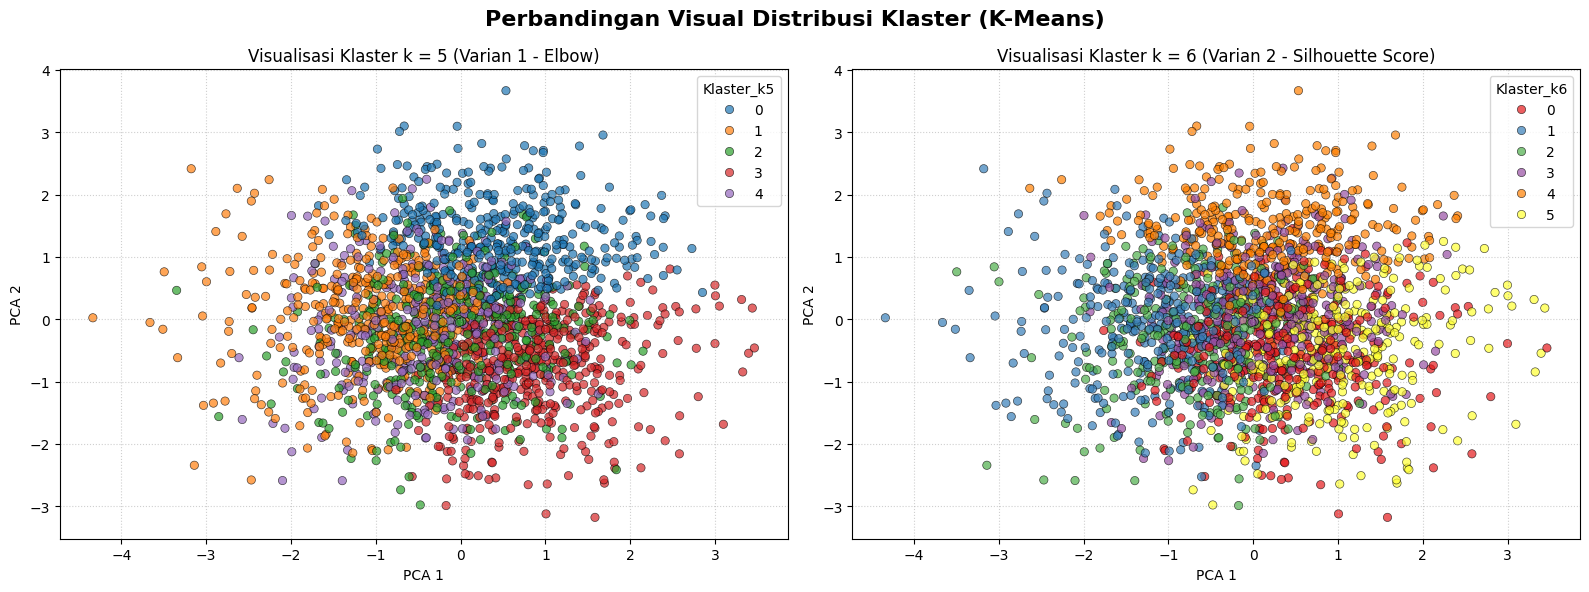

In [161]:
from sklearn.decomposition import PCA
import seaborn as sns

# Reduksi dimensi fitur X menjadi 2 komponen utama
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# Mempersiapkan model untuk k=5
model_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)
labels_k5 = model_k5.fit_predict(X)

# Membuat DataFrame untuk visualisasi
df_pca = pd.DataFrame({
    'PCA 1': X_pca[:, 0],
    'PCA 2': X_pca[:, 1],
    'Klaster_k5': labels_k5,
    'Klaster_k6': klaster_labels
})

# Menggambar Plot Perbandingan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: k=5 (Varian 1)
sns.scatterplot(
    x='PCA 1', y='PCA 2', hue='Klaster_k5', data=df_pca,
    palette='tab10', ax=axes[0], alpha=0.7, edgecolor='k'
)
axes[0].set_title('Visualisasi Klaster k = 5 (Varian 1 - Elbow)')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Subplot 2: k=6 (Varian 2)
sns.scatterplot(
    x='PCA 1', y='PCA 2', hue='Klaster_k6', data=df_pca,
    palette='Set1', ax=axes[1], alpha=0.7, edgecolor='k'
)
axes[1].set_title('Visualisasi Klaster k = 6 (Varian 2 - Silhouette Score)')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Perbandingan Visual Distribusi Klaster (K-Means)', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

### Kesimpulan Akademis dan Implikasi Penelitian

1. **Evaluasi Komparatif (Varian 1 vs Varian 2)**:
   - **Varian 2 ($k = 6$)** memberikan hasil pembagian klaster yang lebih optimal secara matematis berdasarkan metrik *Silhouette Score* (`0.2924`) dibandingkan dengan pendekatan Varian 1 ($k = 5$, `0.2883`). Hal ini membuktikan bahwa penentuan klaster berbasis maksimisasi jarak antarkelompok menghasilkan struktur data yang lebih kohesif.

2. **Justifikasi Ilmiah Peningkatan Jumlah Klaster**:
   - Penambahan jumlah kelompok menjadi $k = 6$ mampu mereduksi bias generalisasi. Model berhasil memisahkan kelompok transisi (seperti responden yang aktif berolahraga namun memiliki *screen time* tinggi) dari kelompok yang benar-benar menjalani pola hidup sehat secara menyeluruh (*Healthy Active Lifestyle*). Analisis ini memberikan landasan teoretis yang lebih tajam dalam mengklasifikasikan tingkat obesitas berdasarkan parameter perilaku sehari-hari.

### Ekspor Model Klastering (Serialisasi `.pkl`)

Sebagai bagian akhir dari alur penelitian ini, model K-Means optimal dengan parameter $k = 6$ disimpan ke dalam format serialisasi objek (`.pkl`). Hal ini bertujuan untuk mendukung aspek ketergunaan kembali model (*reusability*) pada tahap deployment atau analisis lanjutan tanpa perlu melatih ulang model dari awal.

In [162]:
import pickle

# Menentukan path penyimpanan file model
model_pkl_path = '/content/model_kmeans_varian2.pkl'

# Menyimpan objek model_best (KMeans k=6) menggunakan pickle
with open(model_pkl_path, 'wb') as file:
    pickle.dump(model_best, file)

import os
if os.path.exists(model_pkl_path):
    print(f"[BERHASIL] Model KMeans Varian 2 (k=6) telah diekspor!")
    print(f"Lokasi file: {model_pkl_path}")
    print(f"Ukuran file: {os.path.getsize(model_pkl_path)} bytes")
else:
    print("[GAGAL] Terjadi kesalahan dalam proses penyimpanan model.")

[BERHASIL] Model KMeans Varian 2 (k=6) telah diekspor!
Lokasi file: /content/model_kmeans_varian2.pkl
Ukuran file: 9539 bytes
